# 🤖 dVRK Surgical Robot — Peg-Transfer Demo (ICRA 2026 *AI for Robotic Surgery* task)

**Run All** → this notebook builds the competition environment, drives two da Vinci PSM arms
(Large Needle Driver) through the peg-transfer task, and shows an **HTML video with live markups** at the bottom.

| What | Source |
|---|---|
| Peg board, wall, 18 posts, red/blue triangular pegs | official AMBF `pegboard_symmetric_with_wall` ([surgical_robotics_challenge](https://github.com/surgical-robotics-ai/surgical_robotics_challenge)) |
| PSM arms with Large Needle Driver (LND 420006), home poses | official AMBF `PSMs/LND_420006` (same repo) |
| Task rules (left → right, hand-off over the wall) | [competition pages](https://surgical-robotics-ai.github.io/icra-competition-2026/) |
| Camera | 1280×800 equivalent, 80° × 55° FOV (rendered at reduced size), same frame as the AMBF `CameraFrame` |

**Needs:** Internet ON (only to `pip install` and `git clone`). No GPU, no ROS, no Isaac Sim. Runtime ≈ 4–6 min on CPU.

## 1 · Setup (quiet)

In [1]:
import os, sys, subprocess, shutil, time, math, json, base64, io, contextlib, warnings, collections
from pathlib import Path
warnings.filterwarnings("ignore")

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd() / "dvrk_peg_transfer_output"
WORK.mkdir(parents=True, exist_ok=True)
REPOS = WORK / "_repos"; REPOS.mkdir(exist_ok=True)

@contextlib.contextmanager
def quiet():
    """Silence C-level stdout/stderr (PyBullet prints build/warning text from C++)."""
    sys.stdout.flush(); sys.stderr.flush()
    o1, o2 = os.dup(1), os.dup(2); dn = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(dn, 1); os.dup2(dn, 2); yield
    finally:
        os.dup2(o1, 1); os.dup2(o2, 2); os.close(dn); os.close(o1); os.close(o2)

def _sh(cmd, **kw): return subprocess.run(cmd, capture_output=True, text=True, **kw)
def _pip(*pkgs): return _sh([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *pkgs])

def _have(mod):
    try:
        with quiet(): __import__(mod)
        return True
    except Exception: return False

# --- python packages -------------------------------------------------------------------------
for mod, pkg in [("numpy", "numpy"), ("scipy", "scipy"), ("PIL", "pillow"), ("yaml", "pyyaml"),
                 ("shapely", "shapely"), ("trimesh", "trimesh"), ("imageio_ffmpeg", "imageio-ffmpeg")]:
    if not _have(mod): _pip(pkg)

# --- PyBullet (prebuilt wheel if available, otherwise fall back to the arm64/x86 wheel, then source) ---
if not _have("pybullet"):
    for spec in (["--only-binary=:all:", "pybullet"], ["--only-binary=:all:", "pybullet-arm64==3.2.8"], ["pybullet"]):
        _pip(*spec)
        if _have("pybullet"): break
assert _have("pybullet"), "PyBullet could not be installed - turn Internet ON in the notebook settings."

# --- official competition assets (sparse clone: only the two folders we need) ----------------------
CH = REPOS / "surgical_robotics_challenge"
if not (CH / "ADF/PSMs/LND_420006/psm1.yaml").exists():
    shutil.rmtree(CH, ignore_errors=True)
    url = "https://github.com/surgical-robotics-ai/surgical_robotics_challenge.git"
    r = _sh(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse", url, str(CH)])
    if r.returncode == 0:
        _sh(["git", "-C", str(CH), "sparse-checkout", "set", "ADF/PSMs/LND_420006", "ADF/Phantoms/Pegboards"])
    if not (CH / "ADF/PSMs/LND_420006/psm1.yaml").exists():                # fallback: plain shallow clone
        shutil.rmtree(CH, ignore_errors=True)
        r = _sh(["git", "clone", "-q", "--depth", "1", url, str(CH)])
assert (CH / "ADF/PSMs/LND_420006/psm1.yaml").exists(), "could not fetch surgical_robotics_challenge (is Internet ON?)"
PEGBOARD_DIR = CH / "ADF/Phantoms/Pegboards"; PSM_DIR = CH / "ADF/PSMs/LND_420006"

import numpy as np, yaml, trimesh
with quiet(): import pybullet as p
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw, ImageFont
from scipy.spatial.transform import Rotation as Rot, Slerp
from scipy.optimize import least_squares
from shapely.geometry import Polygon
print("✔ environment ready · PyBullet", p.getAPIVersion(), "· assets:", CH.name)

✔ environment ready · PyBullet 202010061 · assets: surgical_robotics_challenge


## 2 · Environment builders (pegboard + PSM arms from the official AMBF files)

In [2]:
# ---------------- frames: AMBF world -> "board frame" (+x image-right, +y image-up/far, +z up, board top = 0) -------
C_BOARD = np.array([0.0193, 0.2320, 0.7239]); R_B = Rot.from_euler("z", math.pi)
to_board = lambda pos: R_B.apply(np.asarray(pos) - C_BOARD)
rot_to_board = lambda R: (R_B * Rot.from_matrix(R)).as_matrix()
unit = lambda v: np.asarray(v, float) / np.linalg.norm(v)

def _v(d): return np.array([d["x"], d["y"], d["z"]], float)
def _ambf_pose(e):
    l = e["location"]; o = l["orientation"]
    return _v(l["position"]), Rot.from_euler("xyz", [o["r"], o["p"], o["y"]]).as_matrix()
def _T(pos, R): T = np.eye(4); T[:3, :3] = R; T[:3, 3] = pos; return T
def _inv(T): Ti = np.eye(4); Ti[:3, :3] = T[:3, :3].T; Ti[:3, 3] = -T[:3, :3].T @ T[:3, 3]; return Ti
_f = lambda a: " ".join(f"{x:.7f}" for x in a)

# ---------------- pegboard ----------------------------------------------------------------------------------------
BLOCK_RGBA = {"red": (0.88, 0.05, 0.04, 1), "blue": (0.05, 0.14, 0.95, 1)}
POST_Z = 0.02      # post height above the board

def block_collision_files(mesh_file, out_dir, k=14):
    """Convex wedges of the block ring (written as OBJ) so a block can really slide over a post."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    m = trimesh.load(mesh_file, force="mesh", process=False)
    sec = m.section(plane_origin=[0, 0, 0.0075], plane_normal=[0, 0, 1])
    loops = sorted([Polygon(l[:, :2]).buffer(0) for l in sec.discrete if len(l) > 3], key=lambda q: q.area, reverse=True)
    outer, hole = loops[0], loops[1]; ring = outer.difference(hole)
    hc = np.array(hole.centroid.coords[0]); files = []; R = 0.03
    for i in range(k):
        a0, a1 = 2 * math.pi * i / k, 2 * math.pi * (i + 1) / k; am = (a0 + a1) / 2
        wedge = Polygon([hc, hc + R * np.array([math.cos(a0), math.sin(a0)]),
                         hc + 1.3 * R * np.array([math.cos(am), math.sin(am)]), hc + R * np.array([math.cos(a1), math.sin(a1)])])
        part = ring.intersection(wedge)
        for g in ([part] if part.geom_type == "Polygon" else [g for g in getattr(part, "geoms", []) if g.geom_type == "Polygon"]):
            if g.area < 1e-8: continue
            pts = np.array(g.convex_hull.exterior.coords)[:-1]
            v = np.vstack([np.c_[pts, np.zeros(len(pts))], np.c_[pts, np.full(len(pts), 0.015)]])
            f = out_dir / f"{Path(mesh_file).stem}_w{len(files):02d}.obj"
            trimesh.convex.convex_hull(v).export(str(f)); files.append(str(f))
    return files

def build_pegboard(blocks):
    """blocks: list of dict(color, post=(x,y), yaw). Returns dict of PyBullet ids."""
    hi, lo = PEGBOARD_DIR / "high_res", PEGBOARD_DIR / "low_res"
    d = yaml.safe_load(open(PEGBOARD_DIR / "pegboard_symmetric_with_wall.yaml"))
    ids = {"posts": {}, "blocks": {}}
    def pose(e): pos, R = _ambf_pose(e); return to_board(pos), rot_to_board(R)
    def static(mesh, e, cs, rgba):
        pos, R = pose(e)
        vs = p.createVisualShape(p.GEOM_MESH, fileName=str(mesh), rgbaColor=rgba)
        return p.createMultiBody(0, cs, vs, basePosition=pos.tolist(), baseOrientation=Rot.from_matrix(R).as_quat().tolist())
    tv = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.7, 0.7, 0.01], rgbaColor=(0.70, 0.70, 0.72, 1))
    tc = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.7, 0.7, 0.01])
    ids["table"] = p.createMultiBody(0, tc, tv, basePosition=[0, 0, -0.0251])
    cs = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.1, 0.0075, 0.05], collisionFramePosition=[0, 0.0075, 0])
    ids["board"] = static(lo / "peg_board_s.OBJ", d["BODY peg_board_s"], cs, (0.10, 0.10, 0.11, 1))
    cs = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.002, 0.05, 0.04])
    ids["wall"] = static(lo / "peg_board_wall_s.OBJ", d["BODY peg_board_wall_s"], cs, (0.22, 0.22, 0.25, 1))
    for b in d["bodies"]:
        n = b.replace("BODY ", "")
        if n.startswith("peg") and n.endswith("_s") and n not in ("peg_board_s", "peg_board_wall_s"):
            pos, _ = pose(d[b])
            cs = p.createCollisionShape(p.GEOM_CAPSULE, radius=0.0018, height=POST_Z - 0.0036,
                                        collisionFrameOrientation=Rot.from_euler("x", math.pi / 2).as_quat().tolist())
            ids["posts"][(round(pos[0], 3), round(pos[1], 3))] = static(lo / f"{n}.OBJ", d[b], cs, (0.92, 0.92, 0.94, 1))
    for blk in blocks:
        src = "block1.OBJ" if blk["color"] == "red" else "block2.OBJ"
        files = block_collision_files(hi / src, WORK / "_collision" / blk["color"])
        vs = p.createVisualShape(p.GEOM_MESH, fileName=str(hi / src), rgbaColor=BLOCK_RGBA[blk["color"]])
        cs = p.createCollisionShapeArray([p.GEOM_MESH] * len(files), fileNames=files, collisionFramePositions=[[0, 0, 0]] * len(files))
        x, y = blk["post"]
        bid = p.createMultiBody(0.02, cs, vs, basePosition=[x, y, 0.0015], baseOrientation=Rot.from_euler("z", blk["yaw"]).as_quat().tolist())
        p.changeDynamics(bid, -1, lateralFriction=0.6, rollingFriction=0.0005, spinningFriction=0.001, linearDamping=0.05, angularDamping=0.05)
        ids["blocks"][blk["color"]] = bid
    return ids

# ---------------- PSM arm: AMBF description -> URDF + numpy FK/IK ------------------------------------------------------
JOINT_LIMITS = {"base link-yaw link": (-1.5, 1.5), "yaw link-pitch end link": (-1.0, 1.0),
                "pitch end link-main insertion link": (0.0, 0.24), "main insertion link-tool roll link": (-3.4, 3.4),
                "tool roll link-tool pitch link": (-1.4, 1.4), "tool pitch link-tool yaw link": (-1.4, 1.4),
                "tool yaw link-tool gripper left link": (0.0, 1.5), "tool yaw link-tool gripper right link": (0.0, 1.5)}
ARM_JOINTS = ["base_link-yaw_link", "yaw_link-pitch_end_link", "pitch_end_link-main_insertion_link",
              "main_insertion_link-tool_roll_link", "tool_roll_link-tool_pitch_link", "tool_pitch_link-tool_yaw_link"]
GRIP_JOINTS = ["tool_yaw_link-tool_gripper_left_link", "tool_yaw_link-tool_gripper_right_link"]
LINK_RGBA = {"tool_roll_link": (0.06, 0.06, 0.07, 1), "tool_pitch_link": (0.50, 0.52, 0.56, 1), "tool_yaw_link": (0.55, 0.57, 0.60, 1),
             "tool_gripper_left_link": (0.86, 0.88, 0.92, 1), "tool_gripper_right_link": (0.86, 0.88, 0.92, 1),
             "main_insertion_link": (0.12, 0.12, 0.13, 1)}
TOOL_R = np.array([[0, 1, 0], [0, 0, -1], [-1, 0, 0]], float)   # tool frame in 'tool yaw link': z=forward(-y), y=jaw-opening(+x)
HINGE_TO_GRASP = 0.0065

def ambf_psm_to_urdf(which, out_dir, name):
    d = yaml.safe_load(open(PSM_DIR / f"{which}.yaml")); out_dir = Path(out_dir); mesh_out = out_dir / "meshes"; mesh_out.mkdir(parents=True, exist_ok=True)
    bodies = {d[b]["name"]: dict(T=_T(*_ambf_pose(d[b])), mesh=d[b]["mesh"]) for b in d["bodies"] if "location" in d[b]}
    joints = [dict(name=d[j]["name"], parent=d[j]["parent"][5:], child=d[j]["child"][5:], type=d[j]["type"],
                   cp=_v(d[j]["child pivot"]), ca=_v(d[j]["child axis"])) for j in d["joints"]]
    Tbase = bodies["base link"]["T"]; LF = {"base link": np.eye(4)}
    for j in joints:
        S = np.eye(4); S[:3, 3] = j["cp"]; LF[j["child"]] = _inv(Tbase) @ bodies[j["child"]]["T"] @ S
    clean = lambda s: s.replace(" ", "_"); robot = ET.Element("robot", name=name)
    for bn, b in bodies.items():
        L = ET.SubElement(robot, "link", name=clean(bn)); dst = mesh_out / (clean(bn) + ".obj"); shutil.copy(PSM_DIR / "high_res" / b["mesh"], dst)
        Tv = _inv(LF[bn]) @ (_inv(Tbase) @ b["T"]); vis = ET.SubElement(L, "visual")
        ET.SubElement(vis, "origin", xyz=_f(Tv[:3, 3]), rpy=_f(Rot.from_matrix(Tv[:3, :3]).as_euler("xyz")))
        ET.SubElement(ET.SubElement(vis, "geometry"), "mesh", filename=str(dst.resolve()))
        inr = ET.SubElement(L, "inertial"); ET.SubElement(inr, "mass", value="0.01")
        ET.SubElement(inr, "inertia", ixx="1e-6", ixy="0", ixz="0", iyy="1e-6", iyz="0", izz="1e-6")
    for j in joints:
        Tj = _inv(LF[j["parent"]]) @ LF[j["child"]]; lo, hi = JOINT_LIMITS[j["name"]]
        J = ET.SubElement(robot, "joint", name=clean(j["name"]), type="prismatic" if j["type"].startswith("pris") else "revolute")
        ET.SubElement(J, "parent", link=clean(j["parent"])); ET.SubElement(J, "child", link=clean(j["child"]))
        ET.SubElement(J, "origin", xyz=_f(Tj[:3, 3]), rpy=_f(Rot.from_matrix(Tj[:3, :3]).as_euler("xyz")))
        ET.SubElement(J, "axis", xyz=_f(j["ca"])); ET.SubElement(J, "limit", lower=str(lo), upper=str(hi), effort="10", velocity="10")
    path = out_dir / f"{name}.urdf"; ET.ElementTree(robot).write(path)
    return path, Tbase

class PSMKinematics:
    """Numpy FK / least-squares IK of the PSM (yaw, pitch, insertion, roll, wrist pitch, wrist yaw), pose of the jaw grasp point."""
    def __init__(self, urdf_path):
        J = {j.get("name"): j for j in ET.parse(urdf_path).getroot().findall("joint")}; self.chain = []
        for n in ARM_JOINTS:
            j = J[n]; o = j.find("origin"); lim = j.find("limit")
            T = _T(np.array(o.get("xyz").split(), float), Rot.from_euler("xyz", np.array(o.get("rpy").split(), float)).as_matrix())
            self.chain.append((j.get("type"), T, unit(np.array(j.find("axis").get("xyz").split(), float))))
            self.lo = getattr(self, "lo", []) + [float(lim.get("lower"))]; self.hi = getattr(self, "hi", []) + [float(lim.get("upper"))]
        self.lo, self.hi = np.array(self.lo), np.array(self.hi); self.base = np.eye(4)
        self.T_tool = _T([0, -HINGE_TO_GRASP, 0], TOOL_R)
    def fk(self, q):
        T = self.base.copy()
        for (typ, To, ax), qi in zip(self.chain, q):
            M = np.eye(4)
            if typ == "revolute": M[:3, :3] = Rot.from_rotvec(ax * qi).as_matrix()
            else: M[:3, 3] = ax * qi
            T = T @ To @ M
        return T @ self.T_tool
    def ik(self, pos, R, q0):
        def res(q):
            T = self.fk(q); return np.r_[(T[:3, 3] - pos) / 5e-4, Rot.from_matrix(R.T @ T[:3, :3]).as_rotvec() / 0.01]
        s = least_squares(res, np.clip(q0, self.lo + 1e-6, self.hi - 1e-6), bounds=(self.lo, self.hi), xtol=1e-9, ftol=1e-9, gtol=1e-9, max_nfev=80)
        T = self.fk(s.x)
        return s.x, np.linalg.norm(T[:3, 3] - pos), np.degrees(np.linalg.norm(Rot.from_matrix(R.T @ T[:3, :3]).as_rotvec()))

def tool_rotation(forward, opening_hint):
    z = unit(forward); y = unit(np.asarray(opening_hint) - np.dot(opening_hint, z) * z); return np.c_[np.cross(y, z), y, z]

class Arm:
    def __init__(self, label, which):
        path, Tb = ambf_psm_to_urdf(which, WORK / "_urdf" / which, which.upper())
        pos, R = to_board(Tb[:3, 3]), rot_to_board(Tb[:3, :3]); self.rcm = pos
        self.K = PSMKinematics(path); self.K.base = _T(pos, R)
        self.rid = p.loadURDF(str(path), basePosition=pos.tolist(), baseOrientation=Rot.from_matrix(R).as_quat().tolist(), useFixedBase=True)
        self.idx = {p.getJointInfo(self.rid, i)[1].decode(): i for i in range(p.getNumJoints(self.rid))}
        for i in range(-1, p.getNumJoints(self.rid)):
            p.setCollisionFilterGroupMask(self.rid, i, 0, 0)
            nm = p.getJointInfo(self.rid, i)[12].decode() if i >= 0 else "base_link"
            p.changeVisualShape(self.rid, i, rgbaColor=LINK_RGBA.get(nm, (0.32, 0.33, 0.37, 1)))
        self.label, self.q, self.grip = label, np.zeros(6), 0.0
        T0 = self.K.fk(self.q); self.pos, self.R = T0[:3, 3].copy(), T0[:3, :3].copy()
        self.ik_err = 0.0; self.state = "IDLE"; self.holding = None; self.offset = None; self.apply()
    def apply(self):
        for jn, v in zip(ARM_JOINTS, self.q): p.resetJointState(self.rid, self.idx[jn], float(v))
        for jn in GRIP_JOINTS: p.resetJointState(self.rid, self.idx[jn], float(self.grip))
    def set_pose(self, pos, R, grip):
        self.pos, self.R, self.grip = np.asarray(pos, float), R, grip
        self.q, ep, er = self.K.ik(self.pos, R, self.q); self.ik_err = max(self.ik_err, ep); self.apply()

# ---------------- cameras ---------------------------------------------------------------------------------------------
CAM_FULL = (1280, 800)                                    # competition stereo camera resolution (80° x 55° FOV)
def make_camera(width, mode="overview"):
    """'overview' = raised third-person view that keeps the whole hand-off in frame (default for the demo video);
       'endoscope' = the official AMBF CameraFrame (55° vertical FOV) used by the competition."""
    W = width; H = int(round(width * CAM_FULL[1] / CAM_FULL[0]))
    if mode == "endoscope":
        eye = to_board([0.01937, 0.35456, 0.90445]); look = R_B.apply([0, -0.6428, -0.7660]); up = R_B.apply([0, -0.7660, 0.6428]); vfov = 55.0
        view = p.computeViewMatrix(eye.tolist(), (eye + look * 0.2).tolist(), up.tolist())
    else:
        vfov = 38.0
        view = p.computeViewMatrix([0.0, -0.17, 0.26], [0.0, 0.0, 0.07], [0, 0, 1])
    proj = p.computeProjectionMatrixFOV(vfov, CAM_FULL[0] / CAM_FULL[1], 0.01, 3.0)
    return dict(W=W, H=H, view=view, proj=proj, VP=np.array(proj).reshape(4, 4).T @ np.array(view).reshape(4, 4).T)
def project(cam, P):
    c = cam["VP"] @ np.r_[np.asarray(P, float), 1.0]; ndc = c[:3] / c[3]
    return ((ndc[0] * 0.5 + 0.5) * cam["W"], (1 - (ndc[1] * 0.5 + 0.5)) * cam["H"])
print("✔ builders defined")

✔ builders defined


## 3 · Task definition, markups and video writer

In [5]:
# ------------------------------------------------------------------ task configuration -------------------------------------
PEGS = [dict(color="red",  pick=(-0.08, 0.00), goal=(0.06, 0.00), yaw=0.476),     # red peg: left-outer post -> right post
        dict(color="blue", pick=(-0.04, 0.03), goal=(0.04, 0.03), yaw=0.388)]     # blue peg: left-inner post -> right post
RENDER_W, FPS, CTRL_HZ, PHYS_SUB = int(os.environ.get("DVRK_RENDER_W", 800)), 15, 60, 4   # video width (px) · fps · control rate · physics sub-steps
CAMERA_MODE = "overview"                                    # "overview" (default) or "endoscope" (official AMBF camera frame)
GRIP_OPEN, GRIP_HOLD, GRIP_IDLE = 1.30, 1.05, 0.20          # jaw half-angle (rad)
H_CARRY, H_HAND = 0.118, np.array([-0.004, 0.0, 0.118])     # transport height (wall top = 0.100 m) · hand-off point (block origin)
H_A, H_B, H_PLACE = 0.0105, 0.0045, 0.002                   # grasp heights on the block for PSM1 (rim) / PSM2 (lower), place height
F_A, F_B = unit([0.30, 0.55, -0.78]), unit([-0.30, 0.55, -0.78])      # tool forward directions
R_A, R_B_ = tool_rotation(F_A, [F_A[1], -F_A[0], 0]), tool_rotation(F_B, [F_B[1], -F_B[0], 0])
COL_A, COL_B = (0, 200, 255), (255, 150, 0)                 # markup colours of PSM1 / PSM2
PHASES = ["Approach", "Grasp", "Lift & carry", "Hand-off", "Place", "Retreat"]

def _font(sz, bold=True):
    for f in (f"/usr/share/fonts/truetype/dejavu/DejaVuSans{'-Bold' if bold else ''}.ttf", "/usr/share/fonts/dejavu/DejaVuSans-Bold.ttf",
              "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf"):
        if os.path.exists(f): return ImageFont.truetype(f, sz)
    try: return ImageFont.load_default(size=sz)
    except TypeError: return ImageFont.load_default()
F_S, F_M, F_L = _font(max(11, RENDER_W // 80)), _font(max(13, RENDER_W // 62)), _font(max(16, RENDER_W // 48))

# ------------------------------------------------------------------ markup renderer -----------------------------------------------
def ring_pts(c, r, n=40): return [(c[0] + r * math.cos(a), c[1] + r * math.sin(a), c[2]) for a in np.linspace(0, 2 * math.pi, n)]
def label(d, xy, txt, fill, font=None, anchor="la", bg=(0, 0, 0, 170)):
    font = font or F_S; box = d.textbbox(xy, txt, font=font, anchor=anchor)
    d.rectangle((box[0] - 4, box[1] - 2, box[2] + 4, box[3] + 2), fill=bg); d.text(xy, txt, fill=fill, font=font, anchor=anchor)

def draw_markups(rgb, seg, S, cam, ids, arms, trails):
    W, H = cam["W"], cam["H"]; img = Image.fromarray(rgb).convert("RGBA"); ov = Image.new("RGBA", img.size, (0, 0, 0, 0)); d = ImageDraw.Draw(ov)
    pr = lambda P: project(cam, P)
    # --- wall + hand-off zone + pick/goal posts
    top = pr((0, -0.04, 0.10)); label(d, (top[0] + 8, top[1] - 4), "WALL · 100 mm", (255, 255, 255, 255), F_S)
    hz = [pr(q) for q in ring_pts(H_HAND, 0.022)]; d.line(hz + [hz[0]], fill=(255, 60, 220, 255), width=2)
    base = pr((H_HAND[0], H_HAND[1], 0.0)); d.line([pr(H_HAND), base], fill=(255, 60, 220, 140), width=1)
    label(d, (pr(H_HAND)[0], pr(H_HAND)[1] - 16), "HAND-OFF ZONE", (255, 120, 235, 255), F_S, anchor="ms")
    if S.get("peg") is not None:
        pg = PEGS[S["peg"]]
        for key, col, txt in (("pick", (255, 220, 0, 255), "PICK"), ("goal", (60, 255, 120, 255), "GOAL")):
            c = (pg[key][0], pg[key][1], 0.0); pts = [pr(q) for q in ring_pts(c, 0.011)]; d.line(pts + [pts[0]], fill=col, width=3)
            q = pr((c[0], c[1], 0.0)); label(d, (q[0], q[1] + 18), txt, col, F_S, anchor="ma")
    # --- tool-tip trails
    for arm, col in zip(arms, (COL_A, COL_B)):
        pts = [pr(q) for q in trails[arm.label]]
        for i in range(1, len(pts)): d.line([pts[i - 1], pts[i]], fill=col + (int(40 + 200 * i / len(pts)),), width=3)
    # --- block bounding boxes from the real segmentation mask
    for colr, bid in ids["blocks"].items():
        ys, xs = np.nonzero((seg & 0xFFFFFF) == bid)
        if len(xs) < 4: continue
        x0, x1, y0, y1 = xs.min() - 6, xs.max() + 6, ys.min() - 6, ys.max() + 6
        c = (255, 70, 60) if colr == "red" else (70, 140, 255); tc = (255, 170, 160) if colr == "red" else (160, 200, 255)
        d.rectangle((x0, y0, x1, y1), outline=c + (255,), width=3)
        label(d, (x0, y0 - 4), f"{colr.upper()} PEG · {S['block_state'][colr]}", tc + (255,), F_S, anchor="lb")
    # --- header
    d.rectangle((0, 0, W, int(H * 0.115)), fill=(8, 12, 20, 205))
    d.text((12, 8), "dVRK PEG TRANSFER  ·  ICRA 2026 AI for Robotic Surgery", fill=(255, 255, 255, 255), font=F_L)
    d.text((12, 8 + F_L.size + 6), f"{S['title']}", fill=(180, 220, 255, 255), font=F_M)
    d.text((W - 12, 8), f"t = {S['t']:5.1f} s", fill=(255, 255, 255, 255), font=F_L, anchor="ra")
    d.text((W - 12, 8 + F_L.size + 6), f"transferred {S['score']}/{len(PEGS)}", fill=(120, 255, 160, 255), font=F_M, anchor="ra")
    # --- phase timeline
    bh = int(H * 0.06); y0 = H - bh; d.rectangle((0, y0, W, H), fill=(8, 12, 20, 215)); cw = W / len(PHASES)
    for i, ph in enumerate(PHASES):
        on = (S["phase"] == ph); d.rectangle((i * cw + 4, y0 + 4, (i + 1) * cw - 4, H - 4), fill=(40, 150, 255, 235) if on else (40, 48, 62, 235))
        d.text((i * cw + cw / 2, y0 + bh / 2), ph, fill=(255, 255, 255, 255) if on else (150, 160, 175, 255), font=F_M, anchor="mm")
    # --- top-view schematic inset
    iw = int(W * 0.26); ih = int(iw * 0.5); ix, iy = W - iw - 10, y0 - ih - 10; sc = iw / 0.22
    d.rectangle((ix, iy, ix + iw, iy + ih), fill=(12, 16, 26, 215), outline=(120, 130, 150, 255))
    tp = lambda x, y: (ix + iw / 2 + x * sc, iy + ih / 2 - y * sc)
    d.rectangle((*tp(-0.1, 0.05), *tp(0.1, -0.05)), outline=(150, 150, 160, 255)); d.line([tp(0, -0.05), tp(0, 0.05)], fill=(255, 255, 255, 255), width=3)
    for (x, y) in ids["posts"]: c = tp(x, y); d.ellipse((c[0] - 2, c[1] - 2, c[0] + 2, c[1] + 2), fill=(200, 200, 210, 255))
    if S.get("peg") is not None:
        for key, col in (("pick", (255, 220, 0, 255)), ("goal", (60, 255, 120, 255))):
            c = tp(*PEGS[S["peg"]][key]); d.ellipse((c[0] - 6, c[1] - 6, c[0] + 6, c[1] + 6), outline=col, width=2)
    c = tp(H_HAND[0], H_HAND[1]); d.ellipse((c[0] - 8, c[1] - 8, c[0] + 8, c[1] + 8), outline=(255, 60, 220, 255), width=2)
    for colr, bid in ids["blocks"].items():
        pos = p.getBasePositionAndOrientation(bid)[0]; c = tp(pos[0], pos[1]); r = 5; cc = tuple(int(255 * v) for v in BLOCK_RGBA[colr][:3])
        d.polygon([(c[0], c[1] - r), (c[0] - r, c[1] + r), (c[0] + r, c[1] + r)], fill=cc + (255,))
    for arm, col in zip(arms, (COL_A, COL_B)):
        c = tp(arm.pos[0], arm.pos[1]); d.rectangle((c[0] - 4, c[1] - 4, c[0] + 4, c[1] + 4), outline=col + (255,), width=2)
    d.text((ix + 6, iy + 3), "TOP VIEW", fill=(190, 200, 215, 255), font=F_S)
    # --- arm labels with jaw state
    for arm, col in zip(arms, (COL_A, COL_B)):
        q = pr(arm.pos); tipx, tipy = q; dx = -95 if arm.label == "PSM1" else 95
        lx = min(max(tipx + dx, 70), W - 70); ly = min(max(tipy + 48, int(H * 0.16)), H - int(H * 0.06) - 3 * F_S.size - 24)
        d.line([(tipx, tipy), (lx, ly - 2)], fill=col + (255,), width=2); d.ellipse((tipx - 5, tipy - 5, tipx + 5, tipy + 5), outline=col + (255,), width=2)
        st = f"HOLDING {arm.holding.upper()}" if arm.holding else arm.state
        label(d, (lx, ly), f"{arm.label}  ·  {st}", col + (255,), F_S, anchor="ma")
        label(d, (lx, ly + F_S.size + 8), f"jaw {math.degrees(2 * arm.grip):.0f}°", (230, 230, 230, 255), F_S, anchor="ma")
    return Image.alpha_composite(img, ov).convert("RGB")
print("✔ markup + task config ready")

✔ markup + task config ready


## 4 · Run the peg-transfer (physics + IK + rendering, streamed straight into the video)

In [6]:
import imageio_ffmpeg
t_wall = time.time()
with quiet():
    p.connect(p.DIRECT); p.setGravity(0, 0, -9.81); p.setTimeStep(1 / 240.0)
    ids = build_pegboard([dict(color=g["color"], post=g["pick"], yaw=g["yaw"]) for g in PEGS])
    arms = [Arm("PSM1", "psm1"), Arm("PSM2", "psm2")]
    for _ in range(240): p.stepSimulation()                     # let pegs settle on their posts
cam = make_camera(RENDER_W, CAMERA_MODE); W, H = cam["W"], cam["H"]
VIDEO = WORK / "dvrk_peg_transfer.mp4"
writer = imageio_ffmpeg.write_frames(str(VIDEO), (W, H), fps=FPS, codec="libx264", pix_fmt_in="rgb24", pix_fmt_out="yuv420p",
                                     quality=7, macro_block_size=2, ffmpeg_log_level="error"); writer.send(None)

S = dict(t=0.0, title="Initial state · both PSMs at home pose", phase="Approach", peg=None, score=0,
         block_state={g["color"]: "ON LEFT POST" for g in PEGS}, snap=[])
trails = {a.label: collections.deque(maxlen=48) for a in arms}
KEYFRAMES, RESULTS, EVENTS = [], [], []
clock, ticks, n_frames = 0.0, 0, 0
carrier = None
HOME = {a.label: (a.pos.copy(), a.R.copy()) for a in arms}
minjerk = lambda s: 10 * s**3 - 15 * s**4 + 6 * s**5
Gb = lambda bp, h: np.asarray(bp, float) + np.array([0, 0, h])

def block_pos(color): return np.array(p.getBasePositionAndOrientation(ids["blocks"][color])[0])
def update_block_states():
    for g in PEGS:
        c = g["color"]; bp = block_pos(c)
        if carrier is not None and carrier.holding == c: S["block_state"][c] = f"CARRIED BY {carrier.label}"
        elif c in S.get("placed", ()): S["block_state"][c] = "PLACED ✓ RIGHT POST"
        elif bp[0] > 0.012: S["block_state"][c] = "ON RIGHT POST"
        else: S["block_state"][c] = "ON LEFT POST"

def carry_update():
    if carrier is not None and carrier.holding:
        T = _T(carrier.pos, carrier.R) @ carrier.offset; bid = ids["blocks"][carrier.holding]
        p.resetBasePositionAndOrientation(bid, T[:3, 3].tolist(), Rot.from_matrix(T[:3, :3]).as_quat().tolist())
        p.resetBaseVelocity(bid, [0, 0, 0], [0, 0, 0])

def attach(arm, color):
    global carrier
    bid = ids["blocks"][color]; pos, q = p.getBasePositionAndOrientation(bid)
    Tb = _T(pos, Rot.from_quat(q).as_matrix()); arm.offset = _inv(_T(arm.pos, arm.R)) @ Tb
    p.changeDynamics(bid, -1, mass=0); arm.holding = color; carrier = arm; EVENTS.append((clock, f"{arm.label} grasps {color} peg"))

def release(arm):
    global carrier
    if carrier is arm and arm.holding:
        bid = ids["blocks"][arm.holding]; p.changeDynamics(bid, -1, mass=0.02); p.resetBaseVelocity(bid, [0, 0, 0], [0, 0, 0]); carrier = None
        EVENTS.append((clock, f"{arm.label} releases {arm.holding} peg"))
    arm.holding = None

def emit_frame():
    global n_frames
    img = p.getCameraImage(W, H, cam["view"], cam["proj"], renderer=p.ER_TINY_RENDERER, shadow=1, lightDirection=[0.3, 0.4, 1.0],
                           flags=p.ER_SEGMENTATION_MASK_OBJECT_AND_LINKINDEX)
    rgb = np.reshape(img[2], (H, W, 4))[:, :, :3].astype(np.uint8); seg = np.reshape(img[4], (H, W)).astype(np.int64)
    update_block_states(); S["t"] = clock
    out = draw_markups(rgb, seg, S, cam, ids, arms, trails); arr = np.asarray(out)
    writer.send(np.ascontiguousarray(arr)); n_frames += 1
    while S["snap"]:
        bio = io.BytesIO(); out.save(bio, "JPEG", quality=88); KEYFRAMES.append((S["snap"].pop(0), bio.getvalue()))

def run_step(phase, title, dur, A=None, B=None, states=(None, None), on_end=None):
    global clock, ticks
    S["phase"] = phase
    if title: S["title"] = title
    plan = []
    for arm, tgt, st in zip(arms, (A, B), states):
        if st: arm.state = st
        if tgt is None: continue
        R1 = tgt.get("R", arm.R); sl = Slerp([0, 1], Rot.from_matrix([arm.R, R1]))
        plan.append((arm, arm.pos.copy(), tgt.get("G", arm.pos), sl, arm.grip, tgt.get("grip", arm.grip)))
    n = max(1, int(round(dur * CTRL_HZ)))
    for i in range(1, n + 1):
        s = minjerk(i / n)
        for arm, p0, p1, sl, g0, g1 in plan: arm.set_pose(p0 + (p1 - p0) * s, sl([s]).as_matrix()[0], g0 + (g1 - g0) * s)
        carry_update()
        for _ in range(PHYS_SUB): p.stepSimulation()
        carry_update()
        clock += 1.0 / CTRL_HZ; ticks += 1
        for arm in arms: trails[arm.label].append(arm.pos.copy())
        if ticks % (CTRL_HZ // FPS) == 0: emit_frame()
    if on_end: on_end()

def snap(name): S["snap"].append(name)

# ------------------------------------------------------------------ the scripted mission -----------------------------------------------------
READY_B = dict(G=np.array([0.055, -0.025, 0.095]), R=R_B_, grip=GRIP_IDLE)
run_step("Approach", "Initial state · both PSMs at home pose", 1.0)
for k, g in enumerate(PEGS):
    c = g["color"]; bid = ids["blocks"][c]; S["peg"] = k; bp0 = block_pos(c); goal = np.array([*g["goal"], 0.0])
    ttl = f"PEG {k + 1}/{len(PEGS)} · {c.upper()} · left post → hand-off over wall → right post"
    run_step("Approach", ttl, 1.8, A=dict(G=Gb(bp0 + [0, 0, 0.045], H_A), R=R_A, grip=GRIP_OPEN), B=READY_B if k == 0 else None, states=("APPROACH", "STANDBY"))
    run_step("Approach", None, 1.0, A=dict(G=Gb(bp0, H_A)), states=("DESCEND", None))
    run_step("Grasp", None, 0.7, A=dict(grip=GRIP_HOLD), states=("CLOSE JAWS", None), on_end=lambda: attach(arms[0], c)); snap(f"{c}-grasp")
    run_step("Lift & carry", None, 1.6, A=dict(G=Gb([bp0[0], bp0[1], H_CARRY], H_A)), states=("LIFT", None))
    preB = Gb(H_HAND, H_B) - 0.035 * F_B
    run_step("Lift & carry", None, 2.0, A=dict(G=Gb(H_HAND, H_A)), B=dict(G=preB, R=R_B_, grip=GRIP_OPEN), states=("CARRY OVER WALL", "APPROACH HAND-OFF"))
    run_step("Hand-off", None, 1.0, B=dict(G=Gb(H_HAND, H_B)), states=("HOLD", "ENGAGE PEG"))
    run_step("Hand-off", None, 0.7, B=dict(grip=GRIP_HOLD), states=("HOLD", "CLOSE JAWS"), on_end=lambda: attach(arms[1], c)); snap(f"{c}-handoff")
    run_step("Hand-off", None, 0.7, A=dict(grip=GRIP_OPEN), states=("RELEASE", "HOLD"), on_end=lambda: arms[0].__setattr__("holding", None))
    run_step("Lift & carry", None, 2.4, A=dict(G=arms[0].pos - 0.07 * F_A, grip=GRIP_IDLE), B=dict(G=Gb([goal[0], goal[1], H_CARRY], H_B)), states=("RETRACT", "CARRY TO GOAL"))
    run_step("Place", None, 1.3, B=dict(G=Gb([goal[0], goal[1], H_PLACE], H_B)), states=("STANDBY", "LOWER ONTO POST"))
    run_step("Place", None, 0.7, B=dict(grip=GRIP_OPEN), states=(None, "RELEASE"), on_end=lambda: release(arms[1]))
    run_step("Place", None, 0.8, states=(None, "SETTLE"))
    fp = block_pos(c); err = float(np.linalg.norm(fp[:2] - goal[:2]) * 1000)
    tilt = float(np.degrees(np.linalg.norm(Rot.from_quat(p.getBasePositionAndOrientation(bid)[1]).as_rotvec()[:2])))
    ok = err <= 3.0 and fp[2] <= 0.006 and tilt <= 10.0
    RESULTS.append(dict(peg=c, pick=g["pick"], goal=g["goal"], err_mm=err, tilt=tilt, ok=ok, t_done=clock))
    if ok: S["score"] += 1; S.setdefault("placed", set()).add(c)
    snap(f"{c}-placed")
    run_step("Retreat", None, 1.2, B=dict(G=arms[1].pos - 0.07 * F_B, grip=GRIP_IDLE), states=(None, "RETRACT"))
S["peg"] = None
run_step("Retreat", f"MISSION COMPLETE · {S['score']}/{len(PEGS)} pegs transferred", 2.0,
         A=dict(G=HOME["PSM1"][0], R=HOME["PSM1"][1], grip=GRIP_IDLE), B=dict(G=HOME["PSM2"][0], R=HOME["PSM2"][1], grip=GRIP_IDLE), states=("HOME", "HOME"))
snap("final"); run_step("Retreat", None, 1.5, states=("IDLE", "IDLE"))
writer.close()
SIM_TIME, WALL = clock, time.time() - t_wall
print(f"✔ mission finished · {S['score']}/{len(PEGS)} pegs · sim {SIM_TIME:.1f} s · {n_frames} frames · worst IK error {max(a.ik_err for a in arms) * 1000:.3f} mm · wall {WALL:.0f} s")

✔ mission finished · 2/2 pegs · sim 36.3 s · 544 frames · worst IK error 0.000 mm · wall 648 s


## 5 · Results — HTML video with markups

peg,"pick post (x,y m)","goal post (x,y m)",final error,tilt,finished,success
RED,"(-0.08, 0.0)","(0.06, 0.0)",0.00,0.0°,15.7 s,✅
BLUE,"(-0.04, 0.03)","(0.04, 0.03)",0.00,0.0°,31.6 s,✅

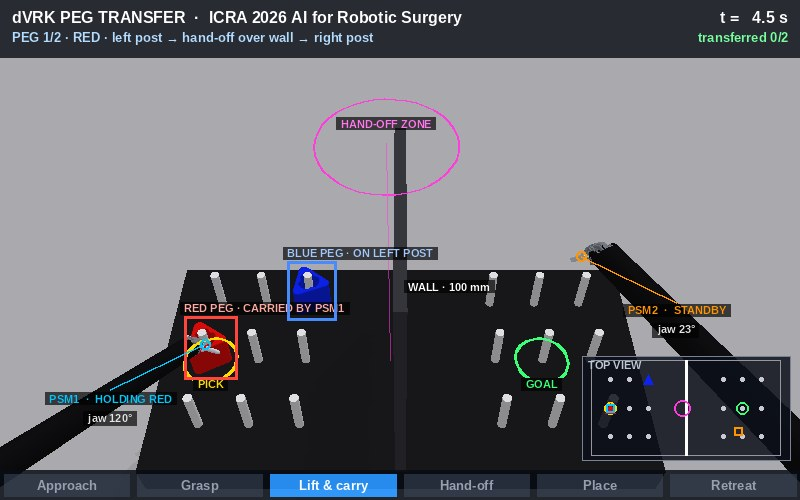
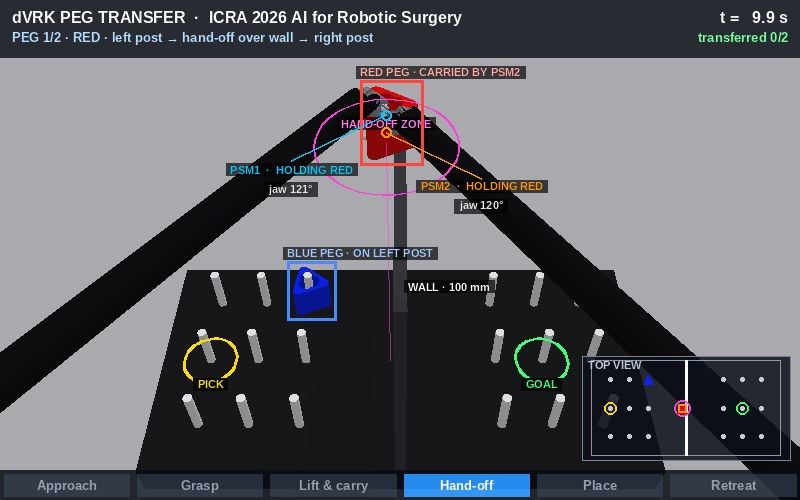
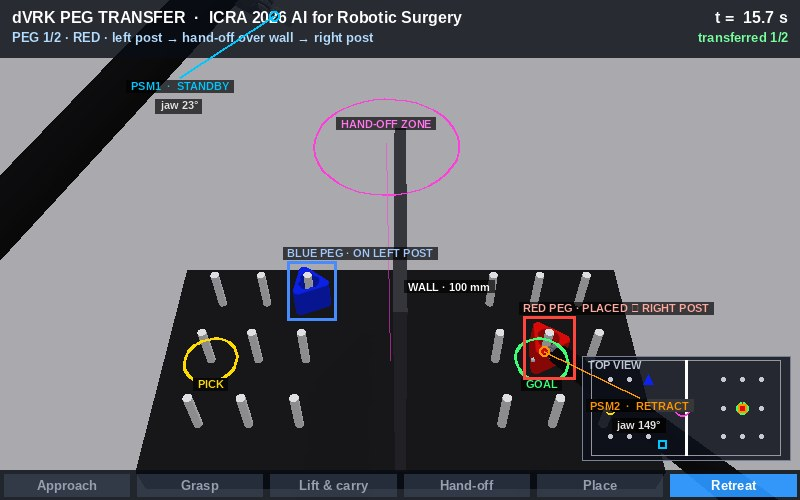
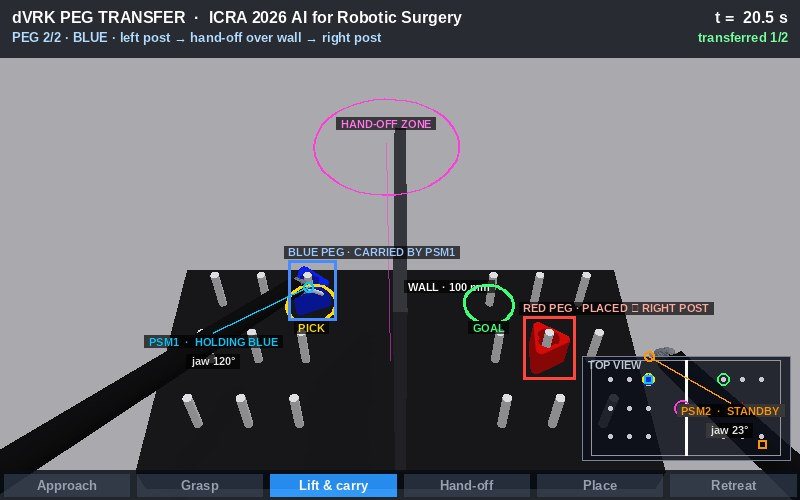
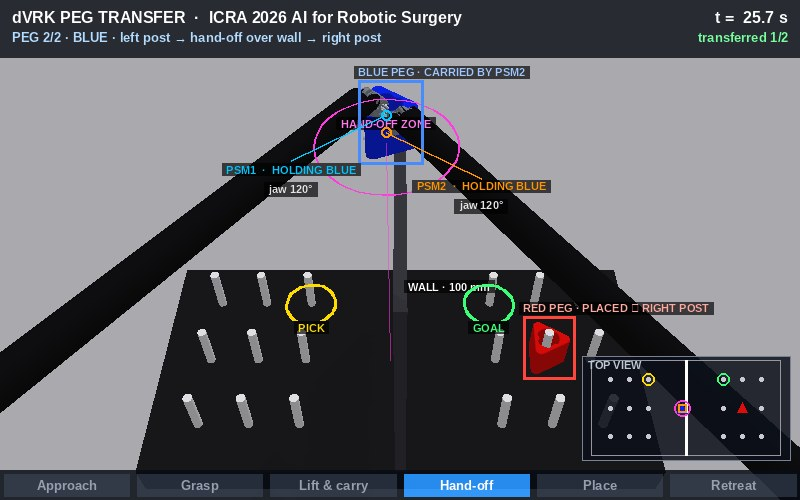
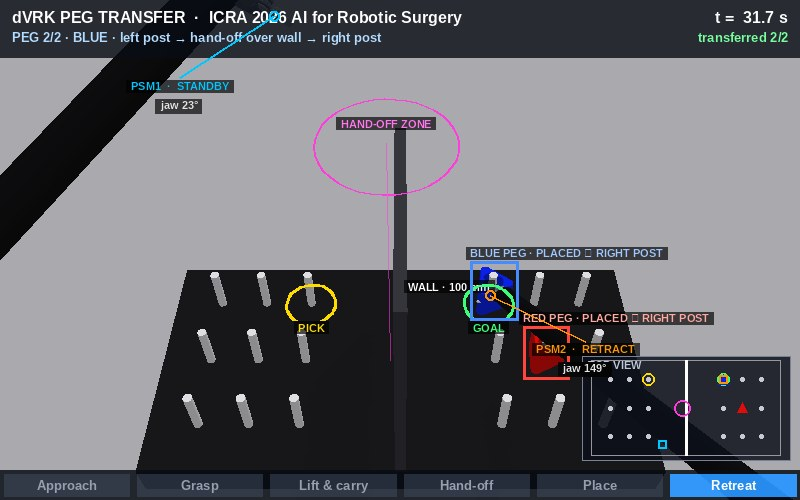

files: /kaggle/working/dvrk_peg_transfer.mp4  ·  /kaggle/working/dvrk_peg_transfer_report.html


In [7]:
from IPython.display import HTML, display
vid_b64 = base64.b64encode(VIDEO.read_bytes()).decode()
kf = "".join(f"<figure style='margin:0;flex:1 1 30%;min-width:260px'><img style='width:100%;border-radius:6px' src='data:image/jpeg;base64,{base64.b64encode(b).decode()}'>"
             f"<figcaption style='font:13px sans-serif;color:#bbb;text-align:center'>{n.replace('-', ' · ')}</figcaption></figure>" for n, b in KEYFRAMES if n != "final")
rows = "".join(f"<tr><td>{r['peg'].upper()}</td><td>{r['pick']}</td><td>{r['goal']}</td><td>{r['err_mm']:.2f}</td><td>{r['tilt']:.1f}°</td><td>{r['t_done']:.1f} s</td><td>{'✅' if r['ok'] else '❌'}</td></tr>" for r in RESULTS)
ev = "".join(f"<li><b>{t:5.1f} s</b> — {m}</li>" for t, m in EVENTS)
REPORT = f"""<div style="background:#0d1117;color:#e6edf3;padding:18px;border-radius:10px;font-family:system-ui,sans-serif;max-width:1100px">
<h2 style="margin:0 0 4px">dVRK peg transfer — ICRA 2026 AI for Robotic Surgery</h2>
<div style="color:#8b949e;margin-bottom:10px">Two PSM arms (LND 420006) · official AMBF pegboard with wall · simulated {SIM_TIME:.1f} s · score <b style="color:#3fb950">{S['score']}/{len(PEGS)}</b></div>
<video controls autoplay loop muted playsinline style="width:100%;border-radius:8px" src="data:video/mp4;base64,{vid_b64}"></video>
<div style="color:#8b949e;font-size:13px;margin:6px 0 14px">Markups: <span style="color:#00c8ff">PSM1</span> / <span style="color:#ff9600">PSM2</span> tool trails &amp; jaw state · peg boxes from the render's segmentation mask ·
<span style="color:#ffdc00">PICK</span> / <span style="color:#3cff78">GOAL</span> posts · <span style="color:#ff78eb">hand-off zone</span> above the 100 mm wall · phase timeline · top-view map.</div>
<h3>Key moments</h3><div style="display:flex;gap:10px;flex-wrap:wrap">{kf}</div>
<h3>Placement results</h3>
<table style="border-collapse:collapse;width:100%;font-size:14px" border="0" cellpadding="6">
<tr style="color:#8b949e;text-align:left"><th>peg</th><th>pick post (x,y m)</th><th>goal post (x,y m)</th><th>final error</th><th>tilt</th><th>finished</th><th>success</th></tr>{rows}</table>
<h3>Event log</h3><ul style="line-height:1.5">{ev}</ul>
<div style="color:#8b949e;font-size:12px">Grasp is modelled as a rigid hold while the jaws are closed on the peg (as in the dVRK PyBullet backend); everything else — arm kinematics, peg/post/wall contact — is simulated.
Video: {W}×{H} px (scaled from the 1280×800 camera, FOV 80°×55°) at {FPS} fps.</div></div>"""
(WORK / "dvrk_peg_transfer_report.html").write_text(f"<!doctype html><meta charset=utf-8><title>dVRK peg transfer</title><body style='margin:0;background:#010409'>{REPORT}</body>")
display(HTML(REPORT))
print(f"files: {VIDEO}  ·  {WORK / 'dvrk_peg_transfer_report.html'}")